## Implement LIME to explain individual predictions by constructing synthetic perturbed datasets, training surrogate models manually, and validating explanations through independent verification techniques.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

df = pd.read_csv('heart.csv')                          
feat = [c for c in df.columns if c != 'target']; n = len(feat)
X, y = df[feat].values.astype(float), df['target'].values
idx = np.random.default_rng(0).permutation(len(X)); cut = int(0.8 * len(X)); tr, te = idx[:cut], idx[cut:]
Xtr = X[tr]

rf = RandomForestClassifier(100, max_depth=5, min_samples_leaf=3, random_state=0).fit(Xtr, y[tr])
f = lambda A: rf.predict_proba(A)[:, 1]               # black-box = P(target = 1)
print('Test accuracy:', np.mean((f(X[te]) > 0.5) == y[te]).round(3), '| features:', n)

Test accuracy: 0.803 | features: 13


In [2]:
def perturb(x, N, rng):
    keep_count = rng.integers(1, n, N)                                    
    rank = rng.random((N, n)).argsort(1).argsort(1)
    Z = rank < keep_count[:, None]                                          
    Z = np.vstack([np.ones(n, bool), Z])                                     
    R = Xtr[rng.integers(0, len(Xtr), (N + 1, n)), np.arange(n)]            
    return Z.astype(float), np.where(Z, x, R)

def kernel(Z, width):
    d = 1 - Z.mean(1)                                                       
    return np.exp(-d ** 2 / width ** 2)                                   

In [3]:
def wridge(Z, t, w, lam=0.01):
    A = np.c_[np.ones(len(Z)), Z]; I = np.eye(A.shape[1]); I[0, 0] = 0              
    theta = np.linalg.solve(A.T @ (A * w[:, None]) + lam * I, A.T @ (w * t))
    return theta[0], theta[1:]

def wr2(Z, t, w, b, beta):                                                        
    res = t - (b + Z @ beta); mu = np.sum(w * t) / w.sum()
    return 1 - np.sum(w * res ** 2) / np.sum(w * (t - mu) ** 2)

def forward_select(Z, t, w, K):                                                      
    S = []
    for _ in range(K):
        best = max((j for j in range(n) if j not in S), key=lambda j: wr2(Z[:, S + [j]], t, w, *wridge(Z[:, S + [j]], t, w)))
        S.append(best)
    return S

def explain(x, N=2000, width=0.5, K=None, seed=0, model=None):
    m = model or f                                                           
    rng = np.random.default_rng(seed); Z, samples = perturb(x, N, rng); t = m(samples); w = kernel(Z, width)
    S = list(range(n)) if K is None else forward_select(Z, t, w, K)
    b, bs = wridge(Z[:, S], t, w); beta = np.zeros(n); beta[S] = bs
    return dict(b=b, beta=beta, r2=wr2(Z, t, w, b, beta), pred=m(x[None])[0], local_pred=b + beta.sum())

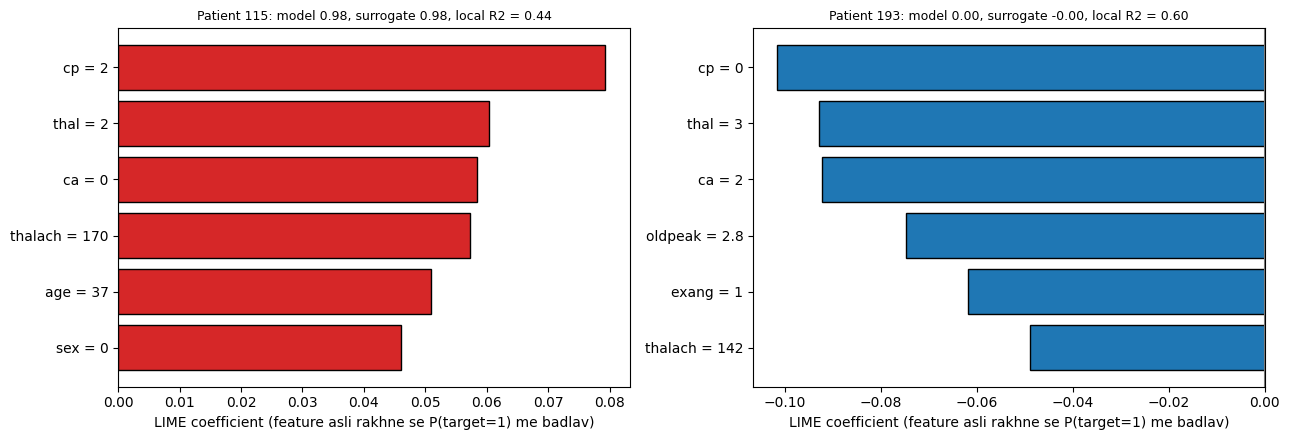

In [4]:
hi, lo = te[np.argmax(f(X[te]))], te[np.argmin(f(X[te]))]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, i in zip(axes, [hi, lo]):
    e = explain(X[i], K=6); sel = [j for j in np.argsort(-np.abs(e['beta'])) if e['beta'][j] != 0][::-1]
    ax.barh(range(len(sel)), e['beta'][sel], color=['tab:red' if e['beta'][j] > 0 else 'tab:blue' for j in sel], edgecolor='k')
    ax.set_yticks(range(len(sel))); ax.set_yticklabels([f'{feat[j]} = {X[i][j]:g}' for j in sel]); ax.axvline(0, color='gray')
    ax.set_xlabel('LIME coefficient (feature asli rakhne se P(target=1) me badlav)')
    ax.set_title(f'Patient {i}: model {e["pred"]:.2f}, surrogate {e["local_pred"]:.2f}, local R2 = {e["r2"]:.2f}', fontsize=9)
plt.tight_layout(); plt.show()

In [5]:
fid_train, fid_new, fid_full, gap = [], [], [], []
for i in te:
    e = explain(X[i], K=6, seed=int(i)); fid_train.append(e['r2']); fid_full.append(explain(X[i], K=None, seed=int(i))['r2'])
    Z, S_ = perturb(X[i], 2000, np.random.default_rng(10_000 + int(i))); t = f(S_); w = kernel(Z, 0.5)    # bilkul naye samples
    fid_new.append(wr2(Z, t, w, e['b'], e['beta'])); gap.append(abs(e['local_pred'] - e['pred']))
print(f'Local R2 (K=6, train perturbations): {np.mean(fid_train):.3f} | naye samples pe: {np.mean(fid_new):.3f} (min {np.min(fid_new):.3f}) | saare 13 features: {np.mean(fid_full):.3f}')
print(f'|surrogate - model| patient pe: mean {np.mean(gap):.3f}, max {np.max(gap):.3f}')

Local R2 (K=6, train perturbations): 0.405 | naye samples pe: 0.399 (min 0.263) | saare 13 features: 0.430
|surrogate - model| patient pe: mean 0.008, max 0.039


In [6]:
rank = lambda v: v.argsort().argsort().astype(float)
spearman = lambda a, b: np.corrcoef(rank(a), rank(b))[0, 1]                       
rho, overlap = [], []
for i in te[:20]:
    B = np.array([explain(X[i], K=None, seed=s)['beta'] for s in range(5)])           
    pairs = [(a, b) for a in range(5) for b in range(a + 1, 5)]
    rho += [spearman(np.abs(B[a]), np.abs(B[b])) for a, b in pairs]
    top = lambda v: set(np.argsort(-np.abs(v))[:3]); overlap += [len(top(B[a]) & top(B[b])) / 3 for a, b in pairs]
print(f'Seeds ke beech Spearman (|coef| ranking): mean {np.mean(rho):.3f}, min {np.min(rho):.3f} | top-3 features overlap: {np.mean(overlap):.0%}')

Seeds ke beech Spearman (|coef| ranking): mean 0.934, min 0.786 | top-3 features overlap: 91%


In [7]:
from math import factorial
bits = ((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1).astype(bool); size = bits.sum(1)
wt = np.array([factorial(k) * factorial(n - k - 1) / factorial(n) for k in range(n)])
bg = Xtr[np.random.default_rng(1).choice(len(Xtr), 40, replace=False)]
def exact_shapley(x):
    v = f(np.where(bits[:, None, :], x[None, None, :], bg[None, :, :]).reshape(-1, n)).reshape(2 ** n, len(bg)).mean(1)
    return np.array([np.sum(wt[size[S]] * (v[S | (1 << i)] - v[S])) for i in range(n) for S in [np.where(~bits[:, i])[0]]])

sub = te[:30]; SH = np.array([exact_shapley(X[i]) for i in sub])
rows = []
for width in [0.25, 0.5, 1.0]:
    L = np.array([explain(X[i], K=None, width=width, seed=int(i))['beta'] for i in sub])
    big = np.abs(SH) > 0.01                                                          
    rows.append((width, np.mean([spearman(L[k], SH[k]) for k in range(len(sub))]), np.mean(np.sign(L)[big] == np.sign(SH)[big]),
                 np.mean([len(set(np.argsort(-np.abs(L[k]))[:3]) & set(np.argsort(-np.abs(SH[k]))[:3])) / 3 for k in range(len(sub))])))
pd.DataFrame(rows, columns=['Kernel width', 'Spearman (signed values)', 'Sign agreement', 'Top-3 overlap']).round(3)

,Kernel width,Spearman (signed values),Sign agreement,Top-3 overlap
0,0.25,0.963,0.993,0.867
1,0.50,0.970,1.000,0.933
2,1.00,0.969,0.997,0.900


In [8]:
rng = np.random.default_rng(5)
def deleted_pred(x, cols, draws=40):
    Zr = np.tile(x, (draws, 1)); Zr[:, cols] = Xtr[rng.integers(0, len(Xtr), (draws, len(cols))), np.array(cols)]      
    return f(Zr).mean()
res = []
for i in te:
    b = explain(X[i], K=None, seed=int(i))['beta']; order = np.argsort(-np.abs(b)); p = f(X[i][None])[0]
    top = abs(p - deleted_pred(X[i], list(order[:3]))); bot = abs(p - deleted_pred(X[i], list(order[-3:])))
    rnd = np.mean([abs(p - deleted_pred(X[i], list(rng.choice(n, 3, replace=False)))) for _ in range(10)])
    res.append((top, rnd, bot))
res = np.array(res)
print(f'Prediction change (mean |dp|): top-3 LIME features hataye = {res[:, 0].mean():.3f} | random 3 = {res[:, 1].mean():.3f} | bottom-3 = {res[:, 2].mean():.3f}')
print(f'Top-3 ne random se zyada badlav kiya: {np.mean(res[:, 0] > res[:, 1]):.0%} patients me | bottom-3 ne random se kam: {np.mean(res[:, 2] < res[:, 1]):.0%}')

Prediction change (mean |dp|): top-3 LIME features hataye = 0.178 | random 3 = 0.085 | bottom-3 = 0.012
Top-3 ne random se zyada badlav kiya: 80% patients me | bottom-3 ne random se kam: 100%


In [9]:
mu, sd = Xtr.mean(0), Xtr.std(0)
lr = LogisticRegression(max_iter=2000).fit((Xtr - mu) / sd, y[tr]); g = lambda A: lr.decision_function((A - mu) / sd)
truth = lr.coef_[0] / sd * (X[te[0]] - Xtr.mean(0))
e = explain(X[te[0]], N=20000, width=1e6, seed=0, model=g)                        
print('Max |LIME - ground truth|:', np.abs(e['beta'] - truth).max().round(3), '| ground truth ka range:', f'{truth.min():+.2f} to {truth.max():+.2f}')
print('Correlation LIME vs truth:', np.corrcoef(e['beta'], truth)[0, 1].round(4))

Max |LIME - ground truth|: 0.033 | ground truth ka range: -0.04 to +1.23
Correlation LIME vs truth: 0.9987
